# Lesson 8 — The 10-minute LLM, end to end

⏱ **Duration:** ~15 min &nbsp;|&nbsp; 📚 **Builds on:** Lessons 0-7 &nbsp;|&nbsp; 💻 **Runs on:** a laptop CPU

**By the end of this lesson you will be able to:**

- run the complete recipe: data → tokenizer → train → evaluate → generate
- interpret the recorded times of a full run
- decide how to spend a 10-minute budget

> 🎤 *Teaching tip:* run the cells in order; every code cell is short enough to be explained live.

## 1. The recipe

Everything from the previous lessons, in one place:

```bash
python scripts/download_full_texts.py   # once
python -m myllm train                   # 10 minutes, 'default' preset
python -m myllm eval
python -m myllm generate "the lord said unto" --seed 1
python -m myllm plot                    # charts in outputs/
```

In this notebook we do the same from Python. The 10-minute training is **opt-in**: set `RUN_FULL_TRAINING = True`
to run it live in class (you can talk through the charts while it trains). Otherwise the notebook uses the model from a previous run.

In [1]:
import sys, warnings
from pathlib import Path

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))  # lets us `import myllm` without installing it

import torch
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
torch.set_num_threads(4)
DATA = ROOT / "data" / "raw"       # training text lives here
MODELS = ROOT / "models"           # checkpoints are written here

In [2]:
RUN_FULL_TRAINING = True     # True -> train the 'default' preset for 10 minutes (blocks the notebook)

from myllm.train import TrainConfig, train, history_path_for
CKPT = MODELS / "model.pt"
if RUN_FULL_TRAINING:
    train(DATA, CKPT, TrainConfig(preset="default"))
assert CKPT.exists(), "No model yet: set RUN_FULL_TRAINING = True (10 min) or run `python -m myllm train`"

corpus: 1,196,318 tokens, vocab 4,000
model: 1,115,264 parameters, budget 10.0 min on cpu
step     0 |    0.0s | train nan | val 8.311 | ppl 4066.4
step   200 |   34.3s | train 4.692 | val 4.670 | ppl 106.7
step   400 |   69.3s | train 4.448 | val 4.338 | ppl 76.6
step   600 |  101.2s | train 4.250 | val 4.269 | ppl 71.4
step   800 |  140.2s | train 4.151 | val 4.127 | ppl 62.0
step  1000 |  187.3s | train 4.123 | val 4.111 | ppl 61.0
step  1200 |  232.3s | train 4.099 | val 3.983 | ppl 53.7
step  1400 |  282.6s | train 3.935 | val 3.958 | ppl 52.4
step  1600 |  334.1s | train 3.979 | val 3.824 | ppl 45.8
step  1800 |  382.4s | train 3.929 | val 3.819 | ppl 45.6
step  2000 |  429.9s | train 3.932 | val 3.833 | ppl 46.2
step  2200 |  479.8s | train 3.861 | val 3.782 | ppl 43.9
step  2400 |  523.5s | train 3.780 | val 3.758 | ppl 42.9
step  2600 |  569.8s | train 3.867 | val 3.711 | ppl 40.9
step  2734 |  600.2s | train 3.773 | val 3.774 | ppl 43.6
done: 2734 steps in 601s, best val loss

## 2. Recorded times and curves

In [3]:
import json, math
meta = json.loads(history_path_for(CKPT).read_text())
t = meta["timings"]
print(f"preset      : {meta['preset']}  ({meta['n_params']:,} parameters, vocab {meta['vocab_size']:,}, batch {meta['batch_size']})")
print(f"corpus      : {meta['corpus_tokens']:,} tokens")
print(f"steps       : {meta['steps']:,}")
print(f"load corpus : {t['load_corpus_s']:6.1f} s")
print(f"tokenize    : {t['tokenize_s']:6.1f} s")
print(f"train       : {t['train_s']:6.1f} s  ({t['train_s']/60:.1f} min)")
print(f"throughput  : {t['tokens_per_s']:,.0f} tokens/s")
print(f"tokens seen : {meta['history'][-1]['tokens']:,}  = {meta['history'][-1]['tokens'] / meta['corpus_tokens']:.1f} passes over the corpus")
print(f"best val    : loss {meta['best_val_loss']:.3f}, perplexity {math.exp(meta['best_val_loss']):.1f}")

preset      : default  (1,115,264 parameters, vocab 4,000, batch 16)
corpus      : 1,196,318 tokens
steps       : 2,734
load corpus :    0.5 s
tokenize    :    1.1 s
train       :  601.4 s  (10.0 min)
throughput  : 4,655 tokens/s
tokens seen : 2,799,616  = 2.3 passes over the corpus
best val    : loss 3.711, perplexity 40.9


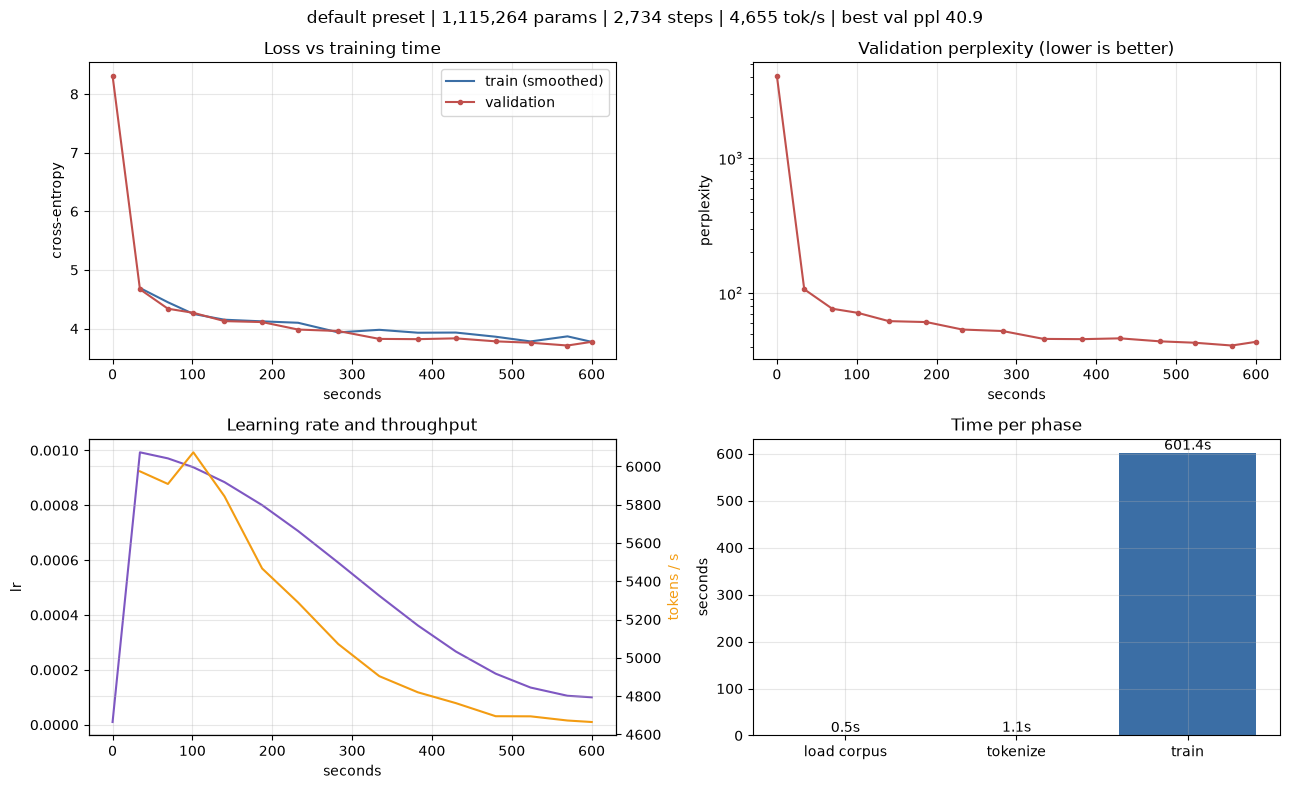

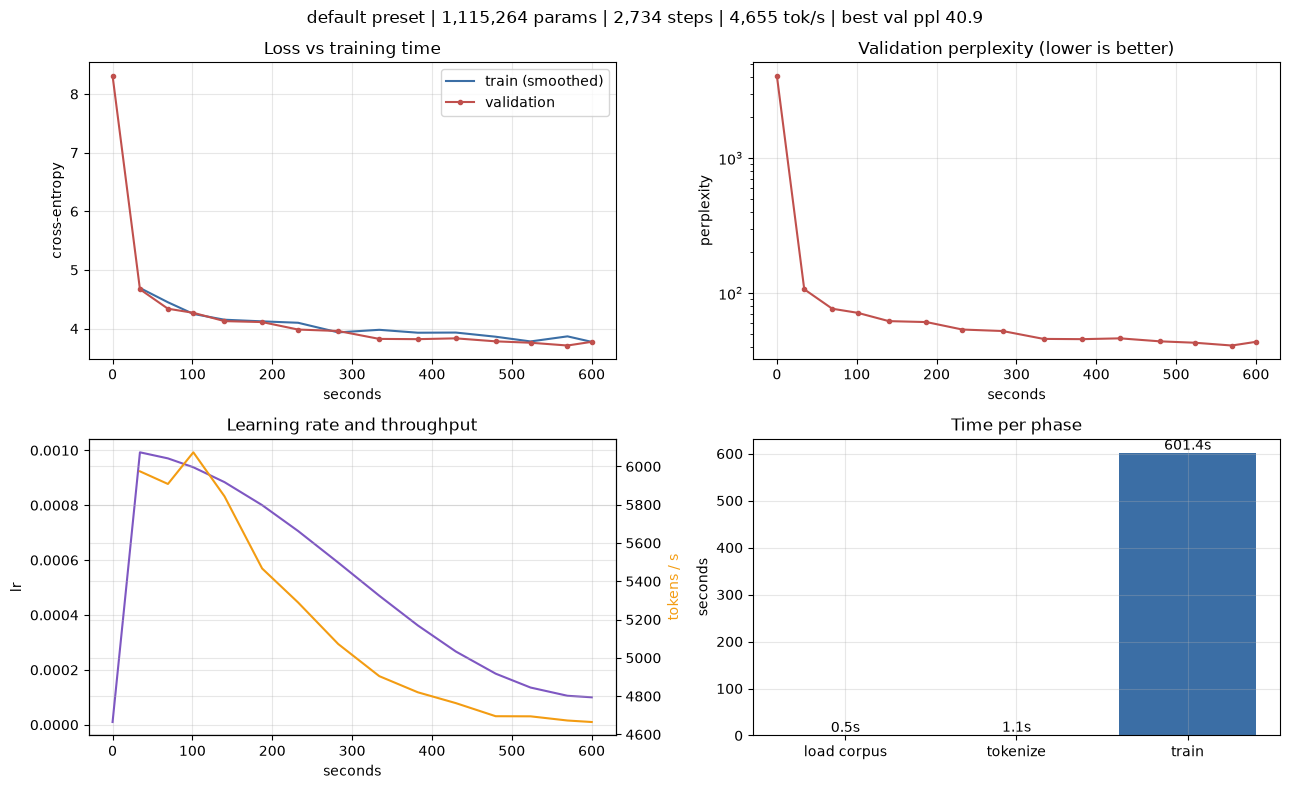

In [4]:
from myllm.plots import training_figure
training_figure(history_path_for(CKPT))

> 💬 **Discussion:** the model saw each token only about twice (*epochs*), and validation loss was still creeping down
> as the learning rate decayed: this model is limited by **compute time**, not by data. A longer run or a GPU would keep helping.

## 3. Evaluate and generate

In [5]:
from myllm.generate import load_checkpoint, generate
from myllm.evaluate import evaluate_heldout
model, tok, info = load_checkpoint(CKPT)
r = evaluate_heldout(model, tok, DATA)
print(f"held-out perplexity {r.perplexity:.1f}, accuracy {r.accuracy:.1%}\n")
for prompt in ("the lord said unto", "a bitcoin transaction", "in the beginning"):
    print(f"▶ {prompt}\n  {generate(model, tok, prompt, 45, seed=2)}\n")

held-out perplexity 42.4, accuracy 29.1%

▶ the lord said unto
  the lord said unto them, and let him go to do not, that they shall be able to jerusalem. 23: 21 and i will go up in your way, and give them you a great people, and not out of your way;

▶ a bitcoin transaction
  a bitcoin transaction (or bob) is the bitcoin address. the transaction is only the same part of the other transaction is the same transaction and the same block transaction of the transaction. you would be included in a block, then it is the

▶ in the beginning
  in the beginning of the lord; he may be found. 4: 14 but the lord hath found the earth, and the people, and the earth shall be of the lord. 22: 5 the lord is not, neither shall he be



## 4. How to spend 10 minutes

| decision | effect | rule of thumb |
|----------|--------|---------------|
| vocabulary 4k vs 8k | bigger = slower steps | smallest vocab with ≲5 % unknown tokens |
| model width/depth | more capacity but fewer steps | with ≤10 min on a CPU keep ~1M parameters |
| context 64 vs 128 | longer context costs time | 64 is enough for sentence-level text |
| learning rate | too high → unstable | 1e-3 with warm-up works for this size |
| time budget | more steps | loss keeps falling: the curve rarely flattens in 10 min |

---
## ✅ Key takeaways

- A full run is data → tokenizer → train → evaluate → generate, and fits in 10 minutes on a CPU.
- All times (load, tokenize, train, tokens/s) are recorded with the checkpoint for later analysis.
- At this scale the model is compute-bound: more time still improves it.

## 🧪 Exercises

1. Train with `--minutes 20`. Predict the validation perplexity first; then check.
2. Compare the model's samples for the three prompts above. Where is it strongest, and why? (hint: lesson 1)
3. Plan a 10-minute budget for *your* laptop: which preset or custom settings would you choose, and why?

## ➡️ Next

**Lesson 9 — Toolbox:** the command line, checkpoints, GPU and troubleshooting.